# Supply Chain & Inventory Analysis
**Meridian Distribution Co.** (fictional company) | January 2024 to December 2025

> All data in this project is **synthetic** and was generated for portfolio demonstration. It does not describe a real business.

## 1. Project objectives
Meridian Distribution Co. buys products from suppliers, stores them in three warehouses and ships them to customers. This notebook explores the data behind the Streamlit dashboard and answers these questions:

1. Which products have the highest inventory value?
2. Which products are running low on stock?
3. How much does the company spend on procurement?
4. Which suppliers deliver on time, and which deliver late?
5. Which product categories have the highest demand?
6. Which products are slow-moving?
7. How has activity changed over time?

**Key definitions** (used in the dashboard too)
- *Inventory value* = current stock x unit cost.
- *Procurement spend* = **ordered** value of purchase-order lines (quantity ordered x unit cost), excluding cancelled orders.
- *Completed delivery* = a purchase order with an actual delivery date. Each purchase order is counted once.
- *On time* = actual delivery date on or before the expected delivery date.

## 2. Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# Project colours
NAVY, TEAL, GREEN, AMBER, RED, GREY = "#172B4D", "#008C95", "#16A34A", "#D97706", "#DC2626", "#94A3B8"

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 20
plt.rcParams.update({
    "figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlecolor": NAVY, "axes.titlesize": 12,
})

DATA_DIR = Path("../data")                  # this notebook lives in notebooks/
SNAPSHOT_DATE = pd.Timestamp("2025-12-31")  # date of the stock snapshot in products.csv
money_axis = FuncFormatter(lambda value, _: f"${value:,.0f}")

## 3. Loading datasets
Five CSV files are used. `opening_balances.csv` holds the stock on hand at the start of 2024, so current stock can be reconciled with the movements.

In [2]:
products = pd.read_csv(DATA_DIR / "products.csv")
suppliers = pd.read_csv(DATA_DIR / "suppliers.csv")
purchase_orders = pd.read_csv(
    DATA_DIR / "purchase_orders.csv",
    parse_dates=["Order_Date", "Expected_Delivery_Date", "Actual_Delivery_Date"],
)
movements = pd.read_csv(DATA_DIR / "inventory_movements.csv", parse_dates=["Date"])
opening = pd.read_csv(DATA_DIR / "opening_balances.csv")

tables = {"products": products, "suppliers": suppliers, "purchase_orders": purchase_orders,
          "inventory_movements": movements, "opening_balances": opening}
for name, table in tables.items():
    print(f"{name:<22}{table.shape[0]:>6} rows {table.shape[1]:>3} columns")

products                 200 rows  10 columns
suppliers                 21 rows   6 columns
purchase_orders         1267 rows  12 columns
inventory_movements     4593 rows   7 columns
opening_balances         200 rows   3 columns


## 4. Data inspection

In [3]:
display(products.head())
display(suppliers.head())

,Product_ID,Product_Name,Category,Supplier_ID,Unit_Cost,Selling_Price,Reorder_Point,Safety_Stock,Current_Stock,Warehouse
0,PRD-001,Poly Bag - Heavy-Duty,Packaging Materials,SUP-01,5.18,7.59,15,5,25,Riverside DC
1,PRD-002,Foam Insert - Heavy-Duty,Packaging Materials,SUP-02,0.79,1.24,17,9,41,Southport DC
2,PRD-003,Foam Insert - Large,Packaging Materials,SUP-01,0.53,0.67,42,19,93,Northgate DC
3,PRD-004,Foam Insert - Medium,Packaging Materials,SUP-02,0.94,1.42,15,5,65,Northgate DC
4,PRD-005,Corrugated Shipping Box - Large,Packaging Materials,SUP-03,0.32,0.41,88,53,298,Northgate DC


,Supplier_ID,Supplier_Name,Region,Supplier_Category,Average_Lead_Time_Days,Contact_Status
0,SUP-01,Pinecrest Packaging,Latin America,Packaging Materials,14,Active
1,SUP-02,BlueHarbor Containers,North America,Packaging Materials,11,On Hold
2,SUP-03,Alder & Finch Paperworks,North America,Packaging Materials,8,Active
3,SUP-04,Ironvale Industrial,Europe,Industrial Supplies,14,Active
4,SUP-05,Granite Ridge Supply,North America,Industrial Supplies,12,Active


In [4]:
display(purchase_orders.head())
display(movements.head())

,PO_ID,PO_Line_ID,Order_Date,Supplier_ID,Product_ID,Quantity_Ordered,Unit_Cost,Total_Cost,Expected_Delivery_Date,Actual_Delivery_Date,Delivery_Status,Quantity_Received
0,PO-00001,PO-00001-01,2024-01-02,SUP-04,PRD-040,155,2.43,376.65,2024-01-16,2024-01-16,Delivered On Time,155
1,PO-00001,PO-00001-02,2024-01-02,SUP-04,PRD-051,105,12.99,"1,363.95",2024-01-16,2024-01-16,Delivered On Time,105
2,PO-00002,PO-00002-01,2024-01-02,SUP-09,PRD-084,30,74.23,"2,226.90",2024-02-03,2024-02-04,Delivered Late,30
3,PO-00002,PO-00002-02,2024-01-02,SUP-09,PRD-098,40,20.34,813.60,2024-02-03,2024-02-04,Delivered Late,40
4,PO-00002,PO-00002-03,2024-01-02,SUP-09,PRD-102,50,89.15,"4,457.50",2024-02-03,2024-02-04,Delivered Late,50


,Movement_ID,Date,Product_ID,Movement_Type,Quantity,Warehouse,Reference_ID
0,MOV-00001,2024-01-01,PRD-001,Stock Out,23,Riverside DC,SO-20001
1,MOV-00002,2024-01-01,PRD-009,Stock Out,76,Riverside DC,SO-20002
2,MOV-00003,2024-01-01,PRD-019,Stock Out,33,Southport DC,SO-20003
3,MOV-00004,2024-01-01,PRD-050,Stock Out,17,Northgate DC,SO-20004
4,MOV-00005,2024-01-01,PRD-053,Stock Out,17,Riverside DC,SO-20005


In [5]:
purchase_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   PO_ID                   1267 non-null   str           
 1   PO_Line_ID              1267 non-null   str           
 2   Order_Date              1267 non-null   datetime64[us]
 3   Supplier_ID             1267 non-null   str           
 4   Product_ID              1267 non-null   str           
 5   Quantity_Ordered        1267 non-null   int64         
 6   Unit_Cost               1267 non-null   float64       
 7   Total_Cost              1267 non-null   float64       
 8   Expected_Delivery_Date  1267 non-null   datetime64[us]
 9   Actual_Delivery_Date    1208 non-null   datetime64[us]
 10  Delivery_Status         1267 non-null   str           
 11  Quantity_Received       1267 non-null   int64         
dtypes: datetime64[us](3), float64(2), int64(2), str(5)
memory u

In [6]:
display(products.describe())
display(movements["Movement_Type"].value_counts())
display(purchase_orders["Delivery_Status"].value_counts())

,Unit_Cost,Selling_Price,Reorder_Point,Safety_Stock,Current_Stock
count,200.00,200.00,200.00,200.00,200.00
mean,20.47,28.69,24.55,9.43,66.00
std,32.61,45.77,18.28,8.15,93.08
min,0.22,0.31,15.00,5.00,0.00
25%,3.10,4.46,15.00,5.00,29.00
50%,7.79,11.22,15.00,5.00,45.00
75%,19.54,26.30,26.00,10.00,65.00
max,192.09,255.88,117.00,56.00,"1,075.00"


Movement_Type
Stock Out     3282
Stock In      1208
Adjustment     103
Name: count, dtype: int64

Delivery_Status
Delivered On Time    986
Delivered Late       222
In Transit            42
Cancelled             14
Overdue                3
Name: count, dtype: int64

## 5. Missing-value and duplicate checks

In [7]:
for name, table in tables.items():
    print(f"{name:<22} missing values: {int(table.isna().sum().sum()):>4} | duplicate rows: {int(table.duplicated().sum())}")

print()
print("Missing values by column in purchase_orders:")
display(purchase_orders.isna().sum()[lambda counts: counts > 0])
print("Delivery status of lines with no actual delivery date:")
display(purchase_orders.loc[purchase_orders["Actual_Delivery_Date"].isna(), "Delivery_Status"].value_counts())

products               missing values:    0 | duplicate rows: 0
suppliers              missing values:    0 | duplicate rows: 0
purchase_orders        missing values:   59 | duplicate rows: 0
inventory_movements    missing values:    0 | duplicate rows: 0
opening_balances       missing values:    0 | duplicate rows: 0

Missing values by column in purchase_orders:


Actual_Delivery_Date    59
dtype: int64

Delivery status of lines with no actual delivery date:


Delivery_Status
In Transit    42
Cancelled     14
Overdue        3
Name: count, dtype: int64

The only missing values are in `Actual_Delivery_Date`. They are expected: orders that are cancelled, still in transit, or overdue have no delivery date yet. These rows are **not** filled in. They are left out of delivery calculations (on-time rate, lead time) and kept in spend and status calculations.

## 6. Data validation and cleaning
Before analysing, check that IDs are unique, relationships are valid, and the numbers add up.

In [8]:
supplier_of_product = products.set_index("Product_ID")["Supplier_ID"]
delivered = purchase_orders["Actual_Delivery_Date"].notna()

checks = {
    "Product IDs are unique": products["Product_ID"].is_unique,
    "Supplier IDs are unique": suppliers["Supplier_ID"].is_unique,
    "PO line IDs are unique": purchase_orders["PO_Line_ID"].is_unique,
    "Every product has a valid supplier": products["Supplier_ID"].isin(suppliers["Supplier_ID"]).all(),
    "Every PO line has a valid product": purchase_orders["Product_ID"].isin(products["Product_ID"]).all(),
    "Every movement has a valid product": movements["Product_ID"].isin(products["Product_ID"]).all(),
    "PO supplier matches the product's supplier": (purchase_orders["Product_ID"].map(supplier_of_product) == purchase_orders["Supplier_ID"]).all(),
    "Total_Cost = Quantity_Ordered x Unit_Cost": ((purchase_orders["Quantity_Ordered"] * purchase_orders["Unit_Cost"]).round(2) - purchase_orders["Total_Cost"]).abs().max() < 0.005,
    "Expected delivery is after order date": (purchase_orders["Expected_Delivery_Date"] > purchase_orders["Order_Date"]).all(),
    "Actual delivery is after order date": (purchase_orders.loc[delivered, "Actual_Delivery_Date"] > purchase_orders.loc[delivered, "Order_Date"]).all(),
    "'Delivered Late' rows are really late": (purchase_orders.loc[purchase_orders["Delivery_Status"] == "Delivered Late", "Actual_Delivery_Date"] > purchase_orders.loc[purchase_orders["Delivery_Status"] == "Delivered Late", "Expected_Delivery_Date"]).all(),
}
for name, passed in checks.items():
    print("PASS" if passed else "FAIL", "-", name)

PASS - Product IDs are unique
PASS - Supplier IDs are unique
PASS - PO line IDs are unique
PASS - Every product has a valid supplier
PASS - Every PO line has a valid product
PASS - Every movement has a valid product
PASS - PO supplier matches the product's supplier
PASS - Total_Cost = Quantity_Ordered x Unit_Cost
PASS - Expected delivery is after order date
PASS - Actual delivery is after order date
PASS - 'Delivered Late' rows are really late


**Stock reconciliation.** Current stock should equal opening stock + Stock In - Stock Out + Adjustments. Each purchase-order receipt appears once, as a Stock In movement that references its PO line, so deliveries are not counted twice.

In [9]:
# Stock Out reduces stock; Stock In adds; Adjustment is already signed (negative = shrinkage)
signed_quantity = movements["Quantity"].where(movements["Movement_Type"] != "Stock Out", -movements["Quantity"])
net_movement = signed_quantity.groupby(movements["Product_ID"]).sum()

expected_stock = opening.set_index("Product_ID")["Opening_Stock"].add(net_movement, fill_value=0)
actual_stock = products.set_index("Product_ID")["Current_Stock"]
print("Products where current stock does not reconcile:", int((expected_stock != actual_stock).sum()))

# Each received PO line should appear exactly once as Stock In
stock_in_refs = movements.loc[movements["Movement_Type"] == "Stock In", "Reference_ID"]
received_lines = purchase_orders.loc[purchase_orders["Quantity_Received"] > 0, "PO_Line_ID"]
print("Received PO lines:", len(received_lines), "| Stock In movements:", len(stock_in_refs))
print("Receipts counted once:", stock_in_refs.is_unique and set(stock_in_refs) == set(received_lines))

Products where current stock does not reconcile: 0
Received PO lines: 1208 | Stock In movements: 1208
Receipts counted once: True


**Cleaning.** The checks found nothing to fix, so no rows were removed or edited. Date columns were parsed when the files were loaded. The next sections add calculated columns (inventory value, stock status, lead time, delay) rather than changing the original values.

## 7. Joining related datasets
The tables are linked by `Product_ID` and `Supplier_ID`. A left join keeps every transaction row, so the row count must not change.

In [10]:
po = (purchase_orders
      .merge(products[["Product_ID", "Product_Name", "Category", "Warehouse"]], on="Product_ID", how="left")
      .merge(suppliers[["Supplier_ID", "Supplier_Name", "Region"]], on="Supplier_ID", how="left"))

mov = movements.merge(products[["Product_ID", "Product_Name", "Category", "Supplier_ID"]], on="Product_ID", how="left")

print("PO lines:", len(purchase_orders), "->", len(po), "| unmatched products:", int(po["Category"].isna().sum()))
print("Movements:", len(movements), "->", len(mov), "| unmatched products:", int(mov["Category"].isna().sum()))

PO lines: 1267 -> 1267 | unmatched products: 0
Movements: 4593 -> 4593 | unmatched products: 0


## 8. Inventory valuation
Inventory value = current stock x unit cost. This describes the **stock snapshot on 31 Dec 2025**, not a historical balance.

In [11]:
products["Inventory_Value"] = products["Current_Stock"] * products["Unit_Cost"]

# Out of Stock: 0 units. Low Stock: above 0 and at or below reorder point. Otherwise Healthy Stock.
products["Stock_Status"] = np.select(
    [products["Current_Stock"] == 0, products["Current_Stock"] <= products["Reorder_Point"]],
    ["Out of Stock", "Low Stock"],
    default="Healthy Stock",
)

total_inventory_value = products["Inventory_Value"].sum()
print(f"Total inventory value: ${total_inventory_value:,.0f}")

value_by_category = (products.groupby("Category")["Inventory_Value"].sum()
                     .sort_values(ascending=False).to_frame("Inventory_Value"))
value_by_category["Share_of_Total_%"] = value_by_category["Inventory_Value"] / total_inventory_value * 100
display(value_by_category)

Total inventory value: $165,704


,Inventory_Value,Share_of_Total_%
Category,,
Tools & Hardware,"50,836.58",30.68
Industrial Supplies,"34,555.30",20.85
Electronics Accessories,"31,753.01",19.16
Safety Equipment,"18,491.28",11.16
Cleaning Supplies,"10,939.41",6.60
Office Supplies,"9,131.64",5.51
Packaging Materials,"5,422.35",3.27
Food Service Supplies,"4,574.56",2.76


In [12]:
top_products = products.nlargest(10, "Inventory_Value")[["Product_Name", "Category", "Current_Stock", "Unit_Cost", "Inventory_Value"]]
display(top_products.reset_index(drop=True))

,Product_Name,Category,Current_Stock,Unit_Cost,Inventory_Value
0,Keyboard - Standard,Electronics Accessories,111,87.23,"9,682.53"
1,Hydraulic Hose - Standard,Industrial Supplies,63,137.61,"8,669.43"
2,Cordless Drill - Compact,Tools & Hardware,65,118.36,"7,693.40"
3,Screwdriver Set - Professional,Tools & Hardware,55,128.42,"7,063.10"
4,Claw Hammer - Compact,Tools & Hardware,59,93.84,"5,536.56"
5,Wireless Mouse - Basic,Electronics Accessories,57,84.89,"4,838.73"
6,Socket Wrench Set - Heavy-Duty,Tools & Hardware,24,192.09,"4,610.16"
7,Drive Chain - Compact,Industrial Supplies,29,137.71,"3,993.59"
8,Safety Gloves - Medium,Safety Equipment,52,76.05,"3,954.60"
9,Work Light - Standard,Tools & Hardware,20,182.84,"3,656.80"


In [13]:
status_counts = products["Stock_Status"].value_counts().reindex(["Healthy Stock", "Low Stock", "Out of Stock"])
display(status_counts.to_frame("Products"))

low_stock_count = int((products["Current_Stock"] <= products["Reorder_Point"]).sum())
print(f"Products at or below reorder point: {low_stock_count} of {len(products)} ({low_stock_count / len(products):.1%})")

# Suggested reorder quantity: top back up to 2 x reorder point, rounded up to a multiple of 5 (a simple rule, not a forecast)
needs_reorder = products[products["Stock_Status"] != "Healthy Stock"].copy()
needs_reorder["Suggested_Reorder_Qty"] = np.ceil((2 * needs_reorder["Reorder_Point"] - needs_reorder["Current_Stock"]).clip(lower=0) / 5) * 5
display(needs_reorder.sort_values(["Stock_Status", "Inventory_Value"], ascending=[False, False])
        [["Product_Name", "Category", "Warehouse", "Current_Stock", "Reorder_Point", "Stock_Status", "Suggested_Reorder_Qty"]]
        .head(10).reset_index(drop=True))

,Products
Stock_Status,
Healthy Stock,176
Low Stock,13
Out of Stock,11


Products at or below reorder point: 24 of 200 (12.0%)


,Product_Name,Category,Warehouse,Current_Stock,Reorder_Point,Stock_Status,Suggested_Reorder_Qty
0,Kraft Mailer - Medium,Packaging Materials,Northgate DC,0,15,Out of Stock,30.00
1,Drive Chain - Standard,Industrial Supplies,Riverside DC,0,20,Out of Stock,40.00
2,Drive Chain - Stainless,Industrial Supplies,Riverside DC,0,34,Out of Stock,70.00
3,Hydraulic Hose - Heavy-Duty,Industrial Supplies,Northgate DC,0,22,Out of Stock,45.00
4,Copy Paper Ream - Premium,Office Supplies,Northgate DC,0,15,Out of Stock,30.00
5,Webcam - Standard,Electronics Accessories,Northgate DC,0,31,Out of Stock,65.00
6,HDMI Cable - Basic,Electronics Accessories,Northgate DC,0,18,Out of Stock,40.00
7,Surge Protector - Basic,Electronics Accessories,Riverside DC,0,15,Out of Stock,30.00
8,Ear Protection - Small,Safety Equipment,Riverside DC,0,15,Out of Stock,30.00
9,Hard Hat - Small,Safety Equipment,Riverside DC,0,15,Out of Stock,30.00


## 9. Procurement spending analysis
Spend is the **ordered value** of non-cancelled purchase-order lines. It shows what was committed, not what was paid or received.

In [14]:
active_po = po[po["Delivery_Status"] != "Cancelled"]
total_spend = active_po["Total_Cost"].sum()
print(f"Total procurement spend (ordered value): ${total_spend:,.0f} across {active_po['PO_ID'].nunique()} purchase orders")

spend_by_year = active_po.groupby(active_po["Order_Date"].dt.year)["Total_Cost"].sum().to_frame("Procurement_Spend")
display(spend_by_year)

monthly_spend = active_po.groupby(active_po["Order_Date"].dt.to_period("M"))["Total_Cost"].sum()
print(f"Highest month: {monthly_spend.idxmax()} (${monthly_spend.max():,.0f}) | lowest month: {monthly_spend.idxmin()} (${monthly_spend.min():,.0f})")

Total procurement spend (ordered value): $1,240,351 across 526 purchase orders


,Procurement_Spend
Order_Date,
2024,"719,796.70"
2025,"520,554.70"


Highest month: 2024-10 ($96,680) | lowest month: 2024-03 ($22,406)


In [15]:
spend_by_supplier = (active_po.groupby("Supplier_Name")["Total_Cost"].sum()
                     .sort_values(ascending=False).to_frame("Procurement_Spend"))
spend_by_supplier["Share_%"] = spend_by_supplier["Procurement_Spend"] / total_spend * 100
display(spend_by_supplier.head(8))

,Procurement_Spend,Share_%
Supplier_Name,,
Kestrel Fasteners,"142,077.85",11.45
Tallgrass Tool Works,"128,154.00",10.33
Ridgeback Hardware,"127,697.40",10.30
Ironvale Industrial,"118,267.30",9.53
Voltline Components,"105,580.80",8.51
Granite Ridge Supply,"100,927.00",8.14
Beacon Protective Wear,"86,506.85",6.97
Cobalt Peak Electronics,"52,158.55",4.21


## 10. Supplier performance calculations
Only **completed** purchase orders (those with an actual delivery date) can be judged. A purchase order is delivered as a whole, so each PO is counted once even if it has several lines.

In [16]:
completed = po[po["Actual_Delivery_Date"].notna()].drop_duplicates("PO_ID").copy()
completed["Lead_Time_Days"] = (completed["Actual_Delivery_Date"] - completed["Order_Date"]).dt.days
completed["Delay_Days"] = (completed["Actual_Delivery_Date"] - completed["Expected_Delivery_Date"]).dt.days
completed["On_Time"] = completed["Delay_Days"] <= 0

overall_on_time = completed["On_Time"].mean() * 100
average_lead_time = completed["Lead_Time_Days"].mean()
print(f"Completed purchase orders: {len(completed)}")
print(f"On-time delivery rate: {overall_on_time:.1f}%")
print(f"Average lead time: {average_lead_time:.1f} days")

Completed purchase orders: 509
On-time delivery rate: 82.1%
Average lead time: 18.6 days


In [17]:
scorecard = completed.groupby("Supplier_Name").agg(
    Completed_Orders=("PO_ID", "count"),
    Avg_Lead_Time_Days=("Lead_Time_Days", "mean"),
    On_Time_Rate=("On_Time", "mean"),
)
scorecard["On_Time_Rate"] *= 100

# Average delay is measured on late orders only
late_orders = completed[completed["Delay_Days"] > 0].groupby("Supplier_Name")["Delay_Days"].agg(Late_Orders="count", Avg_Delay_Days="mean")
scorecard = scorecard.join(late_orders)
scorecard["Late_Orders"] = scorecard["Late_Orders"].fillna(0).astype(int)
scorecard["Avg_Delay_Days"] = scorecard["Avg_Delay_Days"].fillna(0)
scorecard = scorecard.join(active_po.groupby("Supplier_Name")["Total_Cost"].sum().rename("Total_Procurement_Value"))

# Flags: below 75% needs review; below the overall rate is below average
scorecard["Flag"] = np.select(
    [scorecard["Completed_Orders"] < 5, scorecard["On_Time_Rate"] < 75, scorecard["On_Time_Rate"] < overall_on_time],
    ["Low volume", "Needs review", "Below average"],
    default="On track",
)
scorecard = scorecard.sort_values("On_Time_Rate", ascending=False)
display(scorecard[["Completed_Orders", "Total_Procurement_Value", "Avg_Lead_Time_Days", "On_Time_Rate", "Late_Orders", "Avg_Delay_Days", "Flag"]])

,Completed_Orders,Total_Procurement_Value,Avg_Lead_Time_Days,On_Time_Rate,Late_Orders,Avg_Delay_Days,Flag
Supplier_Name,,,,,,,
Pinecrest Packaging,22,"22,818.55",12.82,100.00,0,0.00,On track
Fresh Meadow Hygiene,21,"31,454.20",18.86,95.24,1,17.00,On track
Forge & Anvil Tools,19,"41,031.65",22.37,94.74,1,1.00,On track
BlueHarbor Containers,26,"15,852.45",10.38,92.31,2,6.50,On track
Beacon Protective Wear,24,"86,506.85",21.04,91.67,2,3.50,On track
Larkspur Office Goods,23,"42,158.20",25.13,91.30,2,4.50,On track
Summit Paper & Stationery,27,"25,919.75",5.22,88.89,3,4.33,On track
Harvest Table Disposables,35,"27,166.05",16.97,88.57,4,12.00,On track
Ironvale Industrial,30,"118,267.30",14.07,86.67,4,3.75,On track


## 11. Stock movement and demand analysis
Demand is measured by **Stock Out** movements (units dispatched to customers).

In [18]:
stock_out = mov[mov["Movement_Type"] == "Stock Out"]
print(f"Stock Out movements: {len(stock_out):,} | units dispatched: {stock_out['Quantity'].sum():,}")

units_by_category = stock_out.groupby("Category")["Quantity"].sum().sort_values(ascending=False).to_frame("Units_Dispatched")
units_by_category["Share_%"] = units_by_category["Units_Dispatched"] / units_by_category["Units_Dispatched"].sum() * 100
display(units_by_category)

monthly_units = stock_out.groupby(stock_out["Date"].dt.to_period("M"))["Quantity"].sum()
print(f"Peak month: {monthly_units.idxmax()} ({monthly_units.max():,} units) | lowest month: {monthly_units.idxmin()} ({monthly_units.min():,} units)")

Stock Out movements: 3,282 | units dispatched: 111,271


,Units_Dispatched,Share_%
Category,,
Packaging Materials,25400,22.83
Food Service Supplies,22547,20.26
Industrial Supplies,13757,12.36
Tools & Hardware,11486,10.32
Cleaning Supplies,11166,10.03
Office Supplies,10325,9.28
Electronics Accessories,10181,9.15
Safety Equipment,6409,5.76


Peak month: 2025-11 (7,187 units) | lowest month: 2024-08 (3,093 units)


In [19]:
top_dispatched = (stock_out.groupby("Product_Name")
                  .agg(Units_Dispatched=("Quantity", "sum"), Dispatches=("Movement_ID", "count"))
                  .sort_values("Units_Dispatched", ascending=False).head(10))
display(top_dispatched)

,Units_Dispatched,Dispatches
Product_Name,,
Kraft Mailer - Large,4040,28
Takeout Container - Medium,3637,39
Corrugated Shipping Box - Large,3520,35
Takeout Container - Bulk Pack,2487,35
Stretch Wrap Film - Small,2351,34
Packing Tape - Small,2098,32
Aluminium Foil Pan - Small,1842,13
Ballpoint Pens Box - Value Pack,1746,31
Wireless Mouse - Standard,1609,40


In [20]:
# Slow-moving: stock on hand would last more than 12 months at the average monthly dispatch rate
months_in_data = 24
dispatched = stock_out.groupby("Product_ID")["Quantity"].sum()
slow = products[products["Current_Stock"] > 0].copy()
slow["Avg_Monthly_Dispatch"] = slow["Product_ID"].map(dispatched).fillna(0) / months_in_data
slow["Months_Of_Cover"] = slow["Current_Stock"] / slow["Avg_Monthly_Dispatch"].where(slow["Avg_Monthly_Dispatch"] > 0)
slow = slow[(slow["Months_Of_Cover"] > 12) | slow["Months_Of_Cover"].isna()]

print(f"Slow-moving products: {len(slow)} holding ${slow['Inventory_Value'].sum():,.0f} "
      f"({slow['Inventory_Value'].sum() / total_inventory_value:.0%} of inventory value)")
display(slow.groupby("Category")["Inventory_Value"].agg(["count", "sum"]).rename(columns={"count": "Products", "sum": "Inventory_Value"})
        .sort_values("Inventory_Value", ascending=False))

Slow-moving products: 31 holding $55,012 (33% of inventory value)


,Products,Inventory_Value
Category,,
Tools & Hardware,6,"20,143.94"
Industrial Supplies,4,"13,753.13"
Electronics Accessories,4,"10,311.76"
Safety Equipment,6,"6,684.95"
Packaging Materials,6,"2,022.62"
Cleaning Supplies,1,"1,441.80"
Food Service Supplies,2,514.56
Office Supplies,2,139.70


## 12. Visualizations

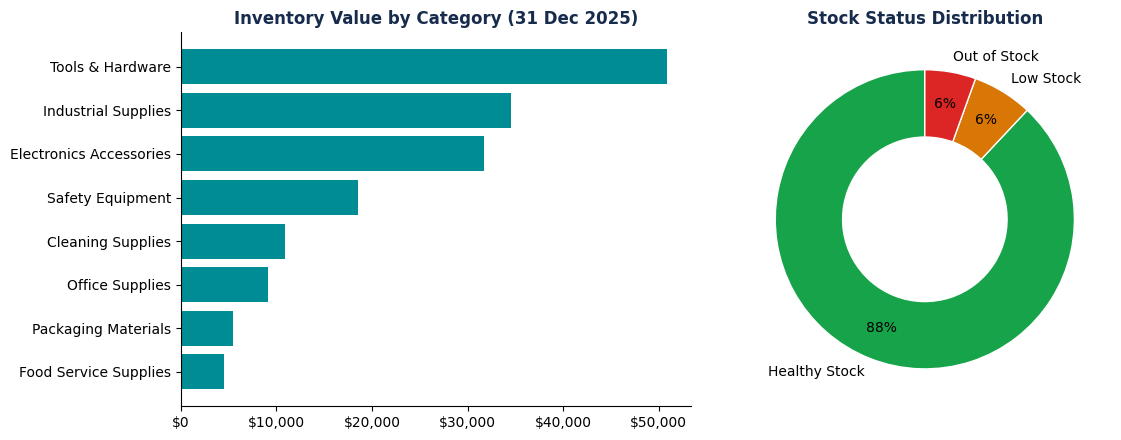

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

by_category = products.groupby("Category")["Inventory_Value"].sum().sort_values()
axes[0].barh(by_category.index, by_category.values, color=TEAL)
axes[0].xaxis.set_major_formatter(money_axis)
axes[0].set_title("Inventory Value by Category (31 Dec 2025)")

colors = {"Healthy Stock": GREEN, "Low Stock": AMBER, "Out of Stock": RED}
axes[1].pie(status_counts.values, labels=status_counts.index, colors=[colors[s] for s in status_counts.index],
            autopct="%1.0f%%", pctdistance=0.78, startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title("Stock Status Distribution")

plt.tight_layout()
plt.show()

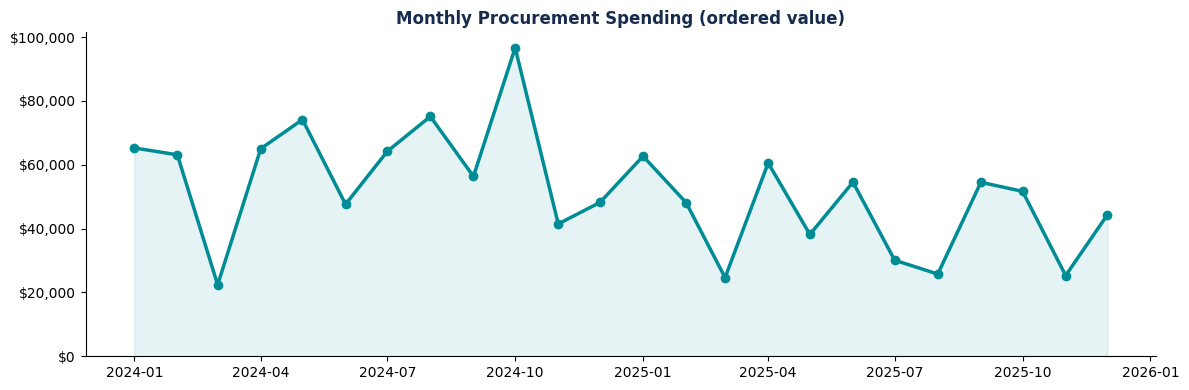

In [22]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly_spend.index = monthly_spend.index.to_timestamp()
ax.plot(monthly_spend.index, monthly_spend.values, color=TEAL, marker="o", linewidth=2.5)
ax.fill_between(monthly_spend.index, monthly_spend.values, color=TEAL, alpha=0.1)
ax.yaxis.set_major_formatter(money_axis)
ax.set_ylim(bottom=0)
ax.set_title("Monthly Procurement Spending (ordered value)")
plt.tight_layout()
plt.show()

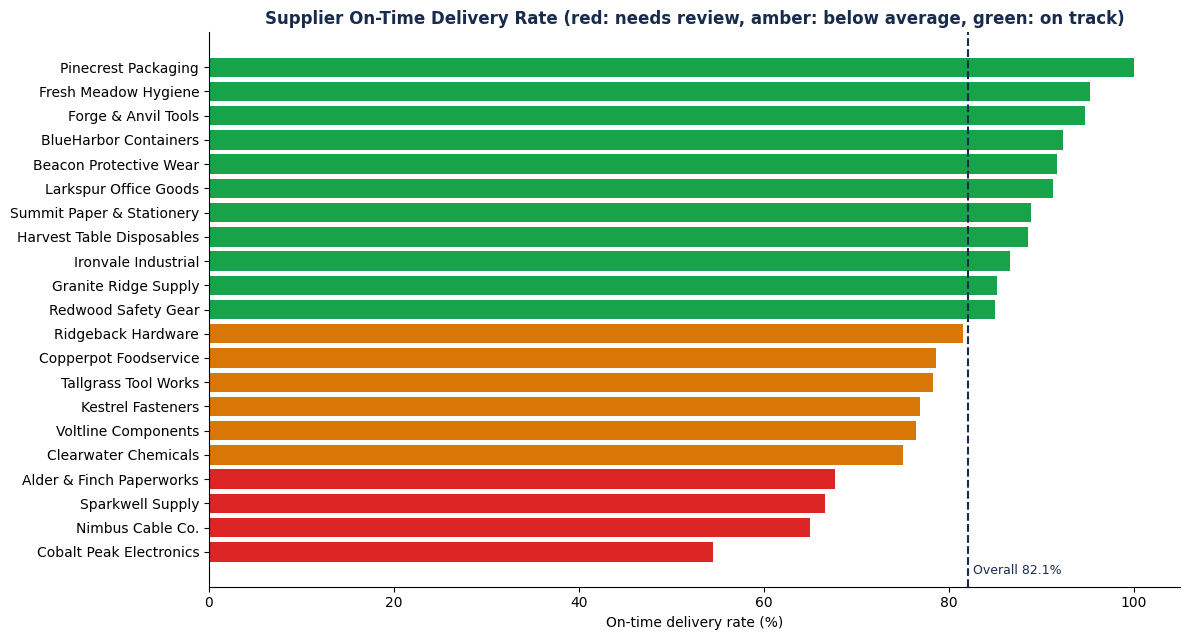

In [23]:
fig, ax = plt.subplots(figsize=(12, 6.5))
rated = scorecard.sort_values("On_Time_Rate")
flag_colors = {"Needs review": RED, "Below average": AMBER, "On track": GREEN, "Low volume": GREY}
ax.barh(rated.index, rated["On_Time_Rate"], color=[flag_colors[f] for f in rated["Flag"]])
ax.axvline(overall_on_time, color=NAVY, linestyle="--")
ax.text(overall_on_time + 0.5, -0.9, f"Overall {overall_on_time:.1f}%", color=NAVY, fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel("On-time delivery rate (%)")
ax.set_title("Supplier On-Time Delivery Rate (red: needs review, amber: below average, green: on track)")
plt.tight_layout()
plt.show()

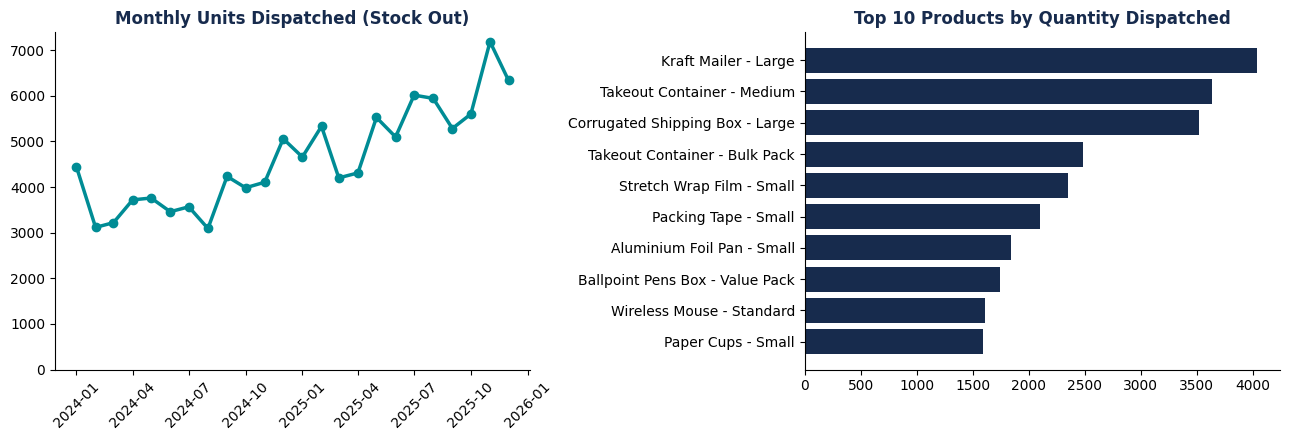

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(monthly_units.index.to_timestamp(), monthly_units.values, color=TEAL, marker="o", linewidth=2.5)
axes[0].set_ylim(bottom=0)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Monthly Units Dispatched (Stock Out)")

top10 = top_dispatched.sort_values("Units_Dispatched")
axes[1].barh(top10.index, top10["Units_Dispatched"], color=NAVY)
axes[1].set_title("Top 10 Products by Quantity Dispatched")

plt.tight_layout()
plt.show()

## 13. Findings and recommendations
The findings below are calculated from the data above, so they always match the tables and charts.

In [25]:
top_category = value_by_category.index[0]
top_supplier = spend_by_supplier.index[0]
rated_suppliers = scorecard[scorecard["Flag"] != "Low volume"]
below_overall = rated_suppliers[rated_suppliers["Flag"].isin(["Needs review", "Below average"])]
lowest_supplier = rated_suppliers["On_Time_Rate"].idxmin()
top_product = top_dispatched.index[0]
slow_category = slow.groupby("Category")["Inventory_Value"].sum().idxmax()

print(f"1. Inventory: {top_category} holds the most inventory value "
      f"({value_by_category['Share_of_Total_%'].iloc[0]:.0f}% of ${total_inventory_value:,.0f}).")
print(f"2. Low stock: {low_stock_count} of {len(products)} products ({low_stock_count / len(products):.1%}) are at or below "
      f"their reorder point, {int(status_counts['Out of Stock'])} of them out of stock.")
print(f"3. Procurement: ${total_spend:,.0f} was ordered. {top_supplier} is the largest supplier "
      f"({spend_by_supplier['Share_%'].iloc[0]:.0f}% of spend).")
print(f"4. Delivery: the overall on-time rate is {overall_on_time:.1f}%. {len(below_overall)} of {len(rated_suppliers)} "
      f"rated suppliers are below it; the lowest is {lowest_supplier} ({rated_suppliers['On_Time_Rate'].min():.1f}%).")
print(f"5. Demand: {units_by_category.index[0]} has the highest dispatch volume "
      f"({units_by_category['Share_%'].iloc[0]:.0f}% of units). The most dispatched product is {top_product}.")
print(f"6. Slow-moving stock: {len(slow)} products tie up ${slow['Inventory_Value'].sum():,.0f}, "
      f"mostly in {slow_category}.")

1. Inventory: Tools & Hardware holds the most inventory value (31% of $165,704).
2. Low stock: 24 of 200 products (12.0%) are at or below their reorder point, 11 of them out of stock.
3. Procurement: $1,240,351 was ordered. Kestrel Fasteners is the largest supplier (11% of spend).
4. Delivery: the overall on-time rate is 82.1%. 10 of 21 rated suppliers are below it; the lowest is Cobalt Peak Electronics (54.5%).
5. Demand: Packaging Materials has the highest dispatch volume (23% of units). The most dispatched product is Kraft Mailer - Large.
6. Slow-moving stock: 31 products tie up $55,012, mostly in Tools & Hardware.


**Recommendations**
- **Review reorder levels** for low-stock and out-of-stock products, starting with the fastest-moving items. The suggested quantities are a simple rule, not a forecast.
- **Investigate late deliveries** for suppliers flagged *Needs review*. Check whether quoted lead times are realistic, and consider ordering earlier from those suppliers.
- **Check slow-moving products** before placing new orders. Smaller order sizes may free up cash.
- **Look at supplier concentration.** The largest suppliers account for a big share of spend, so their delivery performance matters most.

## 14. Data limitations
- **Synthetic data.** Patterns (seasonality, supplier delays, stock levels) were created by a script with a fixed random seed. They show how the analysis works, not how a real business behaves.
- **Stock snapshot.** The dataset holds only the stock level at 31 Dec 2025. Inventory value is not a historical balance, and values before that date would need to be rebuilt from movements.
- **Ordered, not paid.** Procurement spend is ordered value. There is no invoice or payment data, and every delivered order is received in full (no short shipments or returns).
- **Single unit cost per product.** Inventory is valued at the product's current unit cost, not at the cost of each batch received.
- **Simple rules.** The reorder suggestion and slow-moving definition are transparent rules, not forecasts. There is no lead-time demand model or safety-stock optimisation.
- **Small sample.** Each supplier has roughly 17 to 35 completed orders, so on-time rates can move noticeably with a few deliveries.
- **Orders still open.** Orders placed late in December 2025 are still in transit and are excluded from delivery metrics.